In [13]:

import pandas as pd

df = pd.read_csv("student_learning.csv")

df.head()


,hours_studied,attendance,practice_tests,sleep_hours,study_method,final_score,passed
0,7.5,54,0,5.6,video,48,0
1,4.4,61,0,6.0,video,50,0
2,8.2,63,1,5.2,group,73,1
3,6.8,64,1,8.4,self,53,0
4,1.3,79,5,5.8,self,51,0


In [14]:
# Check total rows and columns

print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (280, 7)
Total Rows: 280
Total Columns: 7


In [15]:
# Check data types of all columns

df.dtypes

hours_studied     float64
attendance          int64
practice_tests      int64
sleep_hours       float64
study_method       object
final_score         int64
passed              int64
dtype: object

In [16]:
# Check missing values in each column

df.isnull().sum()


hours_studied     0
attendance        0
practice_tests    0
sleep_hours       0
study_method      0
final_score       0
passed            0
dtype: int64

In [17]:
# Count Passed and Failed students

df["passed"].value_counts()

passed
0    157
1    123
Name: count, dtype: int64

In [18]:
# Calculate percentage of Passed and Failed students

df["passed"].value_counts(normalize=True) * 100

passed
0    56.071429
1    43.928571
Name: proportion, dtype: float64

In [19]:
# Select input features
# We exclude final_score because it causes data leakage

features = [
    "hours_studied",
    "attendance",
    "practice_tests",
    "sleep_hours",
    "study_method"
]

# Create input features (X)
X = df[features]

# Create target variable (y)
y = df["passed"]

# Display input features
X.head()

,hours_studied,attendance,practice_tests,sleep_hours,study_method
0,7.5,54,0,5.6,video
1,4.4,61,0,6.0,video
2,8.2,63,1,5.2,group
3,6.8,64,1,8.4,self
4,1.3,79,5,5.8,self


In [20]:
# Display target variable

y.head()

0    0
1    0
2    1
3    0
4    0
Name: passed, dtype: int64

In [21]:
print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("Selected Features:", features)
print("Target:", y.name)

X Shape: (280, 5)
y Shape: (280,)
Selected Features: ['hours_studied', 'attendance', 'practice_tests', 'sleep_hours', 'study_method']
Target: passed


In [22]:
# Import train_test_split

from sklearn.model_selection import train_test_split

In [23]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [24]:
# Display training and testing shapes

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (224, 5)
X_test: (56, 5)
y_train: (224,)
y_test: (56,)


In [25]:
# Import DummyClassifier

from sklearn.dummy import DummyClassifier

In [14]:
# Create Dummy Baseline Model

dummy_model = DummyClassifier(strategy="most_frequent")

# Train model using training data

dummy_model.fit(X_train, y_train)

DummyClassifier(strategy='most_frequent')

In [15]:
# Predict results on test data

dummy_predictions = dummy_model.predict(X_test)

# Display first 10 predictions

dummy_predictions[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [16]:
# Import accuracy_score

from sklearn.metrics import accuracy_score

# Calculate accuracy

dummy_accuracy = accuracy_score(y_test, dummy_predictions)

print("Dummy Baseline Accuracy:", dummy_accuracy)

Dummy Baseline Accuracy: 0.5535714285714286


In [17]:
# Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

In [18]:
# Preprocessing for numerical columns

numeric_pipeline = Pipeline([

    # Fill missing values using median
    ("imputer", SimpleImputer(strategy="median")),

    # Scale numerical values
    ("scaler", StandardScaler())

])

In [19]:
# Preprocessing for categorical columns

categorical_pipeline = Pipeline([

    # Fill missing values using most frequent value
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Convert text categories into numerical values
    ("encoder", OneHotEncoder(handle_unknown="ignore"))

])

In [20]:
# Select numerical features

numeric_features = [
    "hours_studied",
    "attendance",
    "practice_tests",
    "sleep_hours"
]

# Select categorical features

categorical_features = [
    "study_method"
]

# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer([

    ("numeric", numeric_pipeline, numeric_features),

    ("categorical", categorical_pipeline, categorical_features)

])

In [21]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

In [22]:
# Create Logistic Regression Pipeline

logistic_model = Pipeline([

    # First preprocess the data
    ("preprocessor", preprocessor),

    # Then train Logistic Regression
    ("classifier", LogisticRegression(max_iter=1000))

])

In [23]:
# Train Logistic Regression

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['hours_studied',
                                                   'attendance',
                                                   'practice_tests',
                                                   'sleep_hours']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['study_method'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

In [24]:
# Predict student results on test data

logistic_predictions = logistic_model.predict(X_test)

# Display first 10 predictions

logistic_predictions[:10]

array([1, 0, 0, 1, 0, 0, 0, 1, 0, 0])

In [25]:
# Import evaluation metric

from sklearn.metrics import accuracy_score, f1_score

# Calculate accuracy

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

# Calculate F1 Score

logistic_f1 = f1_score(
    y_test,
    logistic_predictions,
    zero_division=0
)

print("Logistic Regression Accuracy:", logistic_accuracy)

print("Logistic Regression F1 Score:", logistic_f1)

Logistic Regression Accuracy: 0.75
Logistic Regression F1 Score: 0.72


In [27]:
# Import Random Forest

from sklearn.ensemble import RandomForestClassifier

In [28]:
# Create Random Forest Pipeline

random_forest_model = Pipeline([

    # Preprocess the data
    ("preprocessor", preprocessor),

    # Train Random Forest
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))

])

In [29]:
# Train the model

random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['hours_studied',
                                                   'attendance',
                                                   'practice_tests',
                                                   'sleep_hours']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['study_method'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, random_state=42))])

In [30]:
# Predict results on test data

rf_predictions = random_forest_model.predict(X_test)

# Display first 10 predictions

rf_predictions[:10]

array([1, 0, 1, 1, 0, 0, 0, 1, 0, 0])

In [31]:
# Calculate Random Forest Accuracy

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

# Calculate Random Forest F1 Score

rf_f1 = f1_score(
    y_test,
    rf_predictions,
    zero_division=0
)

print("Random Forest Accuracy:", rf_accuracy)

print("Random Forest F1 Score:", rf_f1)

Random Forest Accuracy: 0.7678571428571429
Random Forest F1 Score: 0.7346938775510204


In [32]:
# Compare Logistic Regression and Random Forest

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        logistic_accuracy,
        rf_accuracy
    ],

    "F1 Score": [
        logistic_f1,
        rf_f1
    ]
})

comparison

,Model,Accuracy,F1 Score
0,Logistic Regression,0.750000,0.720000
1,Random Forest,0.767857,0.734694


In [33]:
# Import evaluation metrics

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

In [34]:
# Confusion Matrix for Dummy Model

print("Dummy Baseline Confusion Matrix")

print(confusion_matrix(y_test, dummy_predictions))

# Classification Report

print("\nDummy Baseline Classification Report")

print(classification_report(
    y_test,
    dummy_predictions,
    zero_division=0
))

Dummy Baseline Confusion Matrix
[[31  0]
 [25  0]]

Dummy Baseline Classification Report
              precision    recall  f1-score   support

           0       0.55      1.00      0.71        31
           1       0.00      0.00      0.00        25

    accuracy                           0.55        56
   macro avg       0.28      0.50      0.36        56
weighted avg       0.31      0.55      0.39        56



In [35]:
# Confusion Matrix for Logistic Regression

print("Logistic Regression Confusion Matrix")

print(confusion_matrix(y_test, logistic_predictions))

# Classification Report

print("\nLogistic Regression Classification Report")

print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

Logistic Regression Confusion Matrix
[[24  7]
 [ 7 18]]

Logistic Regression Classification Report
              precision    recall  f1-score   support

           0       0.77      0.77      0.77        31
           1       0.72      0.72      0.72        25

    accuracy                           0.75        56
   macro avg       0.75      0.75      0.75        56
weighted avg       0.75      0.75      0.75        56



In [36]:
# Confusion Matrix for Random Forest

print("Random Forest Confusion Matrix")

print(confusion_matrix(y_test, rf_predictions))

# Classification Report

print("\nRandom Forest Classification Report")

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

Random Forest Confusion Matrix
[[25  6]
 [ 7 18]]

Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.78      0.81      0.79        31
           1       0.75      0.72      0.73        25

    accuracy                           0.77        56
   macro avg       0.77      0.76      0.76        56
weighted avg       0.77      0.77      0.77        56



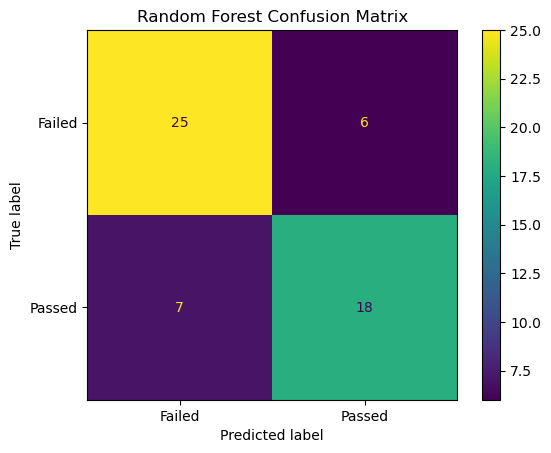

In [37]:
# Import visualization library

import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

# Display Random Forest Confusion Matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_predictions,
    display_labels=["Failed", "Passed"]
)

plt.title("Random Forest Confusion Matrix")

plt.show()

In [2]:
# Import joblib

import joblib

In [3]:
# Create models folder

import os

os.makedirs("models", exist_ok=True)

In [7]:
from sklearn.ensemble import RandomForestClassifier

In [70]:
# Save the complete Random Forest pipeline

joblib.dump(
     random_forest_model,
    "student_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [71]:
# Load saved model without retraining

loaded_model = joblib.load(
    "student_model.joblib"
)

print("Model loaded successfully!")

Model loaded successfully!


In [72]:
# Predict using loaded model

loaded_predictions = loaded_model.predict(X_test)

print("First 10 Predictions:")

print(loaded_predictions[:10])

First 10 Predictions:
[1 0 1 1 0 0 0 1 0 0]


In [73]:
# Check loaded model accuracy

loaded_accuracy = accuracy_score(
    y_test,
    loaded_predictions
)

print("Loaded Model Accuracy:", loaded_accuracy)

Loaded Model Accuracy: 0.7678571428571429


In [74]:
# Read new student records

new_students = pd.read_csv("new_student_records.csv")

# Display new student data

new_students

,hours_studied,attendance,practice_tests,sleep_hours,study_method
0,6.5,90,4,7.5,self
1,5.7,78,5,6.5,video
2,8.0,93,6,8.0,group


In [75]:
# Predict new students without retraining

new_predictions = loaded_model.predict(new_students)

# Display predictions

print("Predictions:", new_predictions)

Predictions: [1 1 1]


In [76]:
# Add predicted class to dataframe

new_students["predicted_passed"] = new_predictions

# Convert 0 and 1 into readable labels

new_students["prediction"] = (
    new_students["predicted_passed"]
    .map({
        0: "Failed",
        1: "Passed"
    })
)

# Display final predictions

new_students

,hours_studied,attendance,practice_tests,sleep_hours,study_method,predicted_passed,prediction
0,6.5,90,4,7.5,self,1,Passed
1,5.7,78,5,6.5,video,1,Passed
2,8.0,93,6,8.0,group,1,Passed


In [77]:
# Save prediction results

new_students.to_csv(
    "new_student_predictions.csv",
    index=False
)

print("Predictions saved successfully!")

Predictions saved successfully!


In [78]:
import sklearn
import sys

print(sklearn.__version__)
print(sys.executable)

1.6.1
E:\ana\python.exe


In [79]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

print("LOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("F1 Score:", f1_score(y_test, logistic_predictions))
print("Confusion Matrix:")
print(confusion_matrix(y_test, logistic_predictions))

print("\nRANDOM FOREST")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("F1 Score:", f1_score(y_test, rf_predictions))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))

LOGISTIC REGRESSION
Accuracy: 0.75
F1 Score: 0.72
Confusion Matrix:
[[24  7]
 [ 7 18]]

RANDOM FOREST
Accuracy: 0.7678571428571429
F1 Score: 0.7346938775510204
Confusion Matrix:
[[25  6]
 [ 7 18]]


In [80]:

import pandas as pd
import joblib

# Load the saved Random Forest pipeline
model = joblib.load("student_model.joblib")

# Load new student records
new_students = pd.read_csv("new_student_records.csv")

# Predict outcomes
predictions = model.predict(new_students)

# Predict probabilities
probabilities = model.predict_proba(new_students)

# Display results
results = new_students.copy()

results["Predicted Outcome"] = [
    "PASS" if p == 1 else "FAIL" for p in predictions
]

results["Pass Probability (%)"] = (
    probabilities[:, 1] * 100
).round(2)

results["Fail Probability (%)"] = (
    probabilities[:, 0] * 100
).round(2)

print(results)


   hours_studied  attendance  practice_tests  sleep_hours study_method  \
0            6.5          90               4          7.5         self   
1            5.7          78               5          6.5        video   
2            8.0          93               6          8.0        group   

  Predicted Outcome  Pass Probability (%)  Fail Probability (%)  
0              PASS                  89.0                  11.0  
1              PASS                  85.0                  15.0  
2              PASS                  99.0                   1.0  


In [81]:
results.to_csv("new_student_predictions.csv", index=False)
print("Prediction results saved successfully!")

Prediction results saved successfully!
